## Choose either dataset to test binary classification. Create a 4-layer Dense network, 
## test with minimum neurons (64, 32, 16, 1), then Increase Units in Dense layers and 
## also Increase Number of Layers add BatchNormalization to Layers add Dropout after Layers.

# Titanic Dataset
https://www.kaggle.com/datasets/valakhorasani/gym-members-exercise-dataset

In [38]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import LabelEncoder 
from sklearn.model_selection import train_test_split

print("ok")

ok


In [39]:
data = pd.read_csv("gym.csv")
data.head(5)

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Workout_Type,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI
0,56,Male,88.3,1.71,180,157,60,1.69,1313.0,Yoga,12.6,3.5,4,3,30.20
1,46,Female,74.9,1.53,179,151,66,1.30,883.0,HIIT,33.9,2.1,4,2,32.00
2,32,Female,68.1,1.66,167,122,54,1.11,677.0,Cardio,33.4,2.3,4,2,24.71
3,25,Male,53.2,1.70,190,164,56,0.59,532.0,Strength,28.8,2.1,3,1,18.41
4,38,Male,46.1,1.79,188,158,68,0.64,556.0,Strength,29.2,2.8,3,1,14.39


In [40]:
# move workout type to end
col_to_move = 'Workout_Type'
cols = [col for col in data.columns if col != col_to_move] + [col_to_move]
data = data[cols]

In [41]:
data.isnull().sum()

Age                              0
Gender                           0
Weight (kg)                      0
Height (m)                       0
Max_BPM                          0
Avg_BPM                          0
Resting_BPM                      0
Session_Duration (hours)         0
Calories_Burned                  0
Fat_Percentage                   0
Water_Intake (liters)            0
Workout_Frequency (days/week)    0
Experience_Level                 0
BMI                              0
Workout_Type                     0
dtype: int64

In [42]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    object 
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Fat_Percentage                 973 non-null    float64
 10  Water_Intake (liters)          973 non-null    float64
 11  Workout_Frequency (days/week)  973 non-null    int64  
 12  Experience_Level               973 non-null    int

In [43]:
# Label encode Object Datatypes 
data_types_dict = dict(data.dtypes)
# Keep track Mappings Column name to LabelEncoders
Label_encoder_collection = {}
for col_name , data_type in data_types_dict.items():
    if data_type == 'object':
        Le = LabelEncoder()
        data[col_name] = Le.fit_transform(data[col_name])
        Label_encoder_collection[col_name] = Le 

data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 973 entries, 0 to 972
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Age                            973 non-null    int64  
 1   Gender                         973 non-null    int64  
 2   Weight (kg)                    973 non-null    float64
 3   Height (m)                     973 non-null    float64
 4   Max_BPM                        973 non-null    int64  
 5   Avg_BPM                        973 non-null    int64  
 6   Resting_BPM                    973 non-null    int64  
 7   Session_Duration (hours)       973 non-null    float64
 8   Calories_Burned                973 non-null    float64
 9   Fat_Percentage                 973 non-null    float64
 10  Water_Intake (liters)          973 non-null    float64
 11  Workout_Frequency (days/week)  973 non-null    int64  
 12  Experience_Level               973 non-null    int

In [44]:
for col_name, label_encoder in Label_encoder_collection.items():
    print(f"Label Encoding mapping for column: {col_name}")
    # Get the mapping (original labels to encoded integers)
    mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
    print(mapping)
    print("-" * 30)

Label Encoding mapping for column: Gender
{'Female': 0, 'Male': 1}
------------------------------
Label Encoding mapping for column: Workout_Type
{'Cardio': 0, 'HIIT': 1, 'Strength': 2, 'Yoga': 3}
------------------------------


In [45]:
num_genres = len(Label_encoder_collection['Workout_Type'].classes_)
num_genres

4

In [46]:
data.head(5)

,Age,Gender,Weight (kg),Height (m),Max_BPM,Avg_BPM,Resting_BPM,Session_Duration (hours),Calories_Burned,Fat_Percentage,Water_Intake (liters),Workout_Frequency (days/week),Experience_Level,BMI,Workout_Type
0,56,1,88.3,1.71,180,157,60,1.69,1313.0,12.6,3.5,4,3,30.20,3
1,46,0,74.9,1.53,179,151,66,1.30,883.0,33.9,2.1,4,2,32.00,1
2,32,0,68.1,1.66,167,122,54,1.11,677.0,33.4,2.3,4,2,24.71,0
3,25,1,53.2,1.70,190,164,56,0.59,532.0,28.8,2.1,3,1,18.41,2
4,38,1,46.1,1.79,188,158,68,0.64,556.0,29.2,2.8,3,1,14.39,2


In [47]:
X = data.iloc[: , :-1].values.astype(np.float32)
Y = data.iloc[: , -1].values.astype(int)

In [48]:
X

array([[ 56.  ,   1.  ,  88.3 , ...,   4.  ,   3.  ,  30.2 ],
       [ 46.  ,   0.  ,  74.9 , ...,   4.  ,   2.  ,  32.  ],
       [ 32.  ,   0.  ,  68.1 , ...,   4.  ,   2.  ,  24.71],
       ...,
       [ 59.  ,   0.  ,  60.4 , ...,   5.  ,   3.  ,  19.5 ],
       [ 32.  ,   1.  , 126.4 , ...,   3.  ,   2.  ,  37.74],
       [ 46.  ,   1.  ,  88.7 , ...,   2.  ,   1.  ,  33.38]],
      dtype=float32)

In [49]:
Y

array([3, 1, 0, 2, 2, 1, 0, 0, 2, 0, 1, 1, 0, 1, 3, 2, 1, 0, 2, 1, 2, 0,
       3, 3, 1, 3, 1, 2, 1, 1, 1, 3, 1, 0, 1, 2, 0, 2, 2, 2, 0, 0, 3, 0,
       1, 2, 3, 0, 2, 0, 3, 0, 0, 2, 1, 0, 3, 0, 0, 1, 2, 3, 2, 2, 2, 0,
       1, 0, 3, 1, 2, 1, 3, 0, 0, 2, 0, 0, 3, 1, 0, 3, 3, 2, 3, 2, 0, 2,
       3, 1, 1, 0, 0, 1, 2, 0, 3, 0, 2, 0, 3, 3, 3, 2, 2, 3, 3, 2, 2, 2,
       1, 2, 3, 1, 2, 3, 0, 1, 3, 0, 3, 2, 2, 0, 2, 3, 0, 3, 3, 3, 2, 2,
       3, 1, 3, 3, 0, 3, 2, 0, 1, 0, 1, 0, 0, 1, 2, 2, 2, 0, 3, 0, 3, 3,
       2, 3, 0, 0, 2, 1, 0, 3, 0, 0, 0, 1, 3, 2, 0, 3, 3, 2, 0, 1, 3, 2,
       1, 3, 0, 3, 1, 1, 0, 0, 2, 0, 2, 1, 1, 3, 3, 2, 0, 0, 3, 1, 2, 1,
       1, 0, 2, 1, 3, 3, 0, 3, 3, 1, 3, 3, 1, 0, 0, 2, 3, 1, 2, 0, 0, 1,
       2, 2, 1, 1, 2, 0, 3, 0, 1, 2, 2, 3, 2, 3, 0, 0, 2, 2, 1, 1, 2, 2,
       0, 2, 1, 0, 3, 1, 1, 0, 3, 1, 2, 1, 0, 0, 0, 1, 3, 2, 0, 3, 2, 0,
       2, 2, 3, 2, 0, 3, 1, 1, 3, 1, 2, 0, 2, 3, 0, 3, 3, 3, 2, 0, 0, 0,
       2, 1, 2, 2, 3, 0, 0, 1, 1, 3, 0, 1, 1, 0, 2,

In [107]:
Xtrain , Xtest , Ytrain , Ytest = train_test_split(X, Y, test_size = 0.5, random_state = 555)

In [108]:
# normalizare
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
Xtrain = scaler.fit_transform(Xtrain)
Xtest = scaler.transform(Xtest)

In [52]:
input_shape = Xtrain.shape[1]

model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(input_shape,)))
model.add(tf.keras.layers.Dense(128, activation='relu'))
model.add(tf.keras.layers.Dense(64, activation='relu'))
model.add(tf.keras.layers.Dense(32, activation='relu'))
model.add(tf.keras.layers.Dense(num_genres, activation='softmax'))  # pentru clasificare multi-class

# print summary to undertstand your neural network flow
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 128)            │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,388 (48.39 KB)

 Trainable params: 12,388 (48.39 KB)

 Non-trainable params: 0 (0.00 B)

In [53]:
Optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
model.compile(Optimizer, loss='sparse_categorical_crossentropy', metrics=["accuracy"])

In [54]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest), epochs=40)

Epoch 1/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - accuracy: 0.2611 - loss: 1.4416 - val_accuracy: 0.2641 - val_loss: 1.3999
Epoch 2/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.2765 - loss: 1.3656 - val_accuracy: 0.2385 - val_loss: 1.4094
Epoch 3/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3207 - loss: 1.3602 - val_accuracy: 0.2436 - val_loss: 1.4251
Epoch 4/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4241 - loss: 1.3006 - val_accuracy: 0.2308 - val_loss: 1.4650
Epoch 5/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.3943 - loss: 1.2844 - val_accuracy: 0.2974 - val_loss: 1.4140
Epoch 6/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4175 - loss: 1.2609 - val_accuracy: 0.2462 - val_loss: 1.4858
Epoch 7/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4348 - loss: 1.2248 - val_accuracy: 0.2385 - val_loss: 1.5815
Epoch 8/40
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.5011 - loss: 1.1833 - val_accuracy: 0.2564 - val_loss

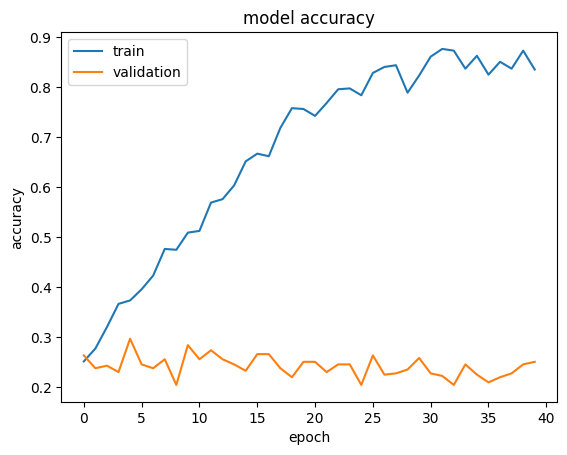

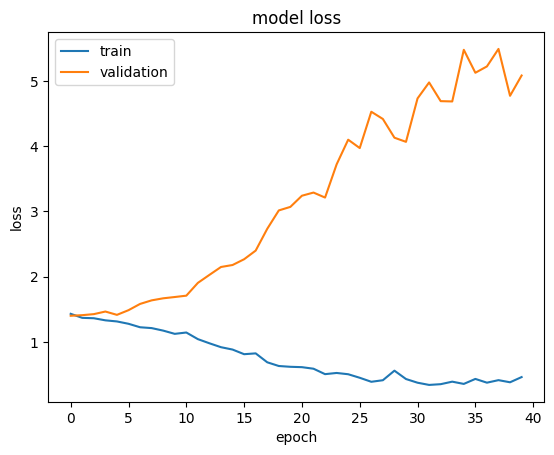

In [55]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# "Loss Plot"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

In [56]:
predictions = np.argmax(model.predict(Xtest), axis=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


In [57]:
from sklearn.metrics import accuracy_score , confusion_matrix
accuracy_score(Ytest , predictions) # Accuracy Seems good

0.2512820512820513

In [58]:
confusion_matrix(Ytest , predictions)

array([[24, 19, 21, 33],
       [23, 22, 24, 30],
       [26, 19, 24, 35],
       [20, 16, 26, 28]])

In [59]:
from sklearn.metrics import classification_report 
print(classification_report(Ytest, predictions, zero_division=0))

              precision    recall  f1-score   support

           0       0.26      0.25      0.25        97
           1       0.29      0.22      0.25        99
           2       0.25      0.23      0.24       104
           3       0.22      0.31      0.26        90

    accuracy                           0.25       390
   macro avg       0.26      0.25      0.25       390
weighted avg       0.26      0.25      0.25       390



In [60]:
# we will try to improve our model's performance 
# ----------- Add class weights when Data is Imbalanced -----------------------
from sklearn.utils.class_weight import compute_class_weight
class_weights = compute_class_weight(class_weight = 'balanced',  classes = np.unique(Ytrain), y=Ytrain)

model_class_weights = {}
for e , weight in enumerate(class_weights):
    model_class_weights[e] = weight

In [61]:
model_class_weights

{0: 0.9224683544303798,
 1: 1.194672131147541,
 2: 0.9464285714285714,
 3: 0.9781879194630873}

In [73]:
history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=20, class_weight=model_class_weights)

Epoch 1/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3287 - loss: 1.3911 - val_accuracy: 0.2744 - val_loss: 1.4460
Epoch 2/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3581 - loss: 1.3467 - val_accuracy: 0.2615 - val_loss: 1.4470
Epoch 3/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3271 - loss: 1.3749 - val_accuracy: 0.2744 - val_loss: 1.4467
Epoch 4/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.3610 - loss: 1.3798 - val_accuracy: 0.2744 - val_loss: 1.4421
Epoch 5/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.4146 - loss: 1.3165 - val_accuracy: 0.2821 - val_loss: 1.4368
Epoch 6/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.3796 - loss: 1.3198 - val_accuracy: 0.2769 - val_loss: 1.4407
Epoch 7/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3730 - loss: 1.3673 - val_accuracy: 0.2744 - val_loss: 1.4375
Epoch 8/20
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3602 - loss: 1.3324 - val_accuracy: 0.2641 - val

In [63]:
predictions = np.argmax(model.predict(Xtest), axis=1)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


In [64]:
from sklearn.metrics import confusion_matrix
confusion_matrix(Ytest, predictions)

array([[28, 19, 18, 32],
       [26, 21, 18, 34],
       [29, 26, 16, 33],
       [26, 24, 15, 25]])

In [110]:
# Increase Units in Dense layers and Also Increase Number of Layers 
# Add BatchNormalization to Layers 
# Add Dropout after Layers 

model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(input_shape,)))

model.add(tf.keras.layers.Dense(128 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(64 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.3))

model.add(tf.keras.layers.Dense(32 , activation='relu'))
model.add(tf.keras.layers.BatchNormalization())
model.add(tf.keras.layers.Dropout(0.2))

model.add(tf.keras.layers.Dense(num_genres , activation='softmax'))

# model = tf.keras.models.Sequential()
# model.add(tf.keras.Input(shape=(input_shape,)))
# model.add(tf.keras.layers.Dropout(0.8))
# model.add(tf.keras.layers.Dense(128, activation='relu'))
# model.add(tf.keras.layers.Dropout(0.2))
# model.add(tf.keras.layers.Dense(64, activation='relu'))
# model.add(tf.keras.layers.Dropout(0.2))
# model.add(tf.keras.layers.Dense(32, activation='relu'))
# model.add(tf.keras.layers.Dense(num_genres, activation='softmax'))  # pentru clasificare multi-class

# print summary to undertstand your neural network flow
# model.summary()

Optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
# Optimizer = tf.keras.optimizers.SGD(learning_rate=0.01)
model.compile(Optimizer, loss='sparse_categorical_crossentropy', metrics=["accuracy"])

history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=20)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step - accuracy: 0.2290 - loss: 2.0457 - val_accuracy: 0.2156 - val_loss: 1.4179
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3097 - loss: 1.9086 - val_accuracy: 0.2136 - val_loss: 1.4209
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2935 - loss: 1.7509 - val_accuracy: 0.2074 - val_loss: 1.4224
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3199 - loss: 1.7414 - val_accuracy: 0.2012 - val_loss: 1.4261
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3015 - loss: 1.6963 - val_accuracy: 0.2053 - val_loss: 1.4269
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2479 - loss: 1.6537 - val_accuracy: 0.2259 - val_loss: 1.4277
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3155 - loss: 1.5716 - val_accuracy: 0.2238 - val_loss: 1.4325
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.2685 - loss: 1.5625 - val_accuracy: 0.2341 - v

In [66]:
# Optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
# model.compile(Optimizer, loss='sparse_categorical_crossentropy', metrics=["accuracy"])

In [67]:
# history = model.fit(Xtrain , Ytrain , validation_data=(Xtest , Ytest) , epochs=40)

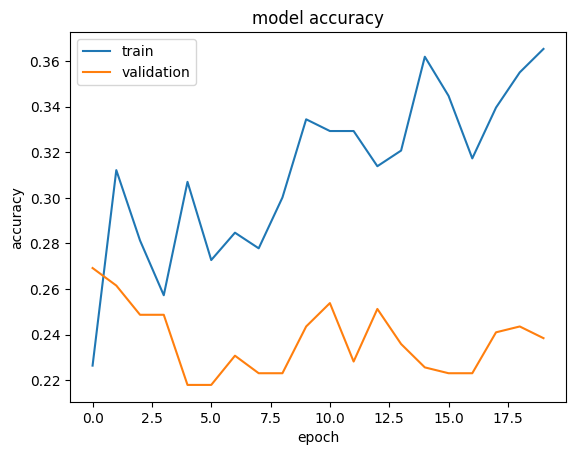

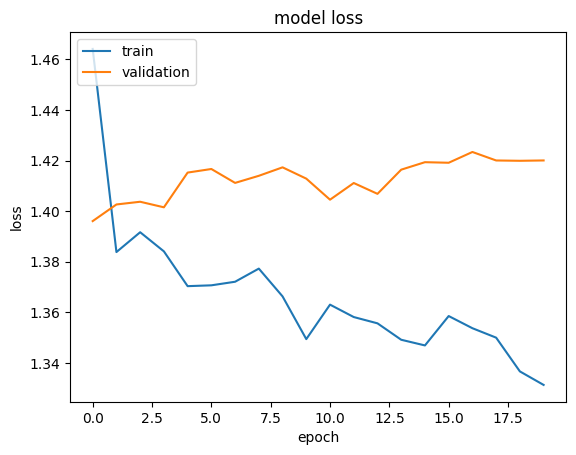

In [101]:
#  "Accuracy Plot"
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# "Loss Plot"
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()

# We see graphs converging better compared to previous implementation

In [102]:
# collect predictions 
predictions = np.argmax(model.predict(Xtest), axis=1)
# Check Accuracy
accuracy_score(Ytest , predictions) # Accuracy is good

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 


0.23846153846153847

In [103]:
# We don't see the problem of predicting everything as class 0
confusion_matrix(Ytest , predictions)

array([[20, 14, 38, 25],
       [37, 14, 31, 17],
       [37, 10, 35, 22],
       [23,  8, 35, 24]])

In [80]:
print(classification_report(Ytest, predictions))

              precision    recall  f1-score   support

           0       0.28      0.42      0.34        97
           1       0.33      0.17      0.23        99
           2       0.25      0.28      0.26       104
           3       0.22      0.19      0.20        90

    accuracy                           0.27       390
   macro avg       0.27      0.27      0.26       390
weighted avg       0.27      0.27      0.26       390

